In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from utils import *

In [2]:
spectra_data = pd.read_csv('OPTIR/Pilot_Phase_Field_Samples_subs2/data_all_spectral.csv')
del spectra_data['Unnamed: 0']

#spectra_data_bg = pd.read_csv('OPTIR/Blank/data_background.csv')
#del spectra_data_bg['Unnamed: 0']

In [18]:
spectra_data_non_bg = pd.read_csv('OPTIR/Pilot_Phase_Field_Samples/data_all.csv')
spectra_data_bg = pd.read_csv('OPTIR/Pilot_Phase_Field_Samples/data_background.csv')

In [26]:
bg_indicator = np.concatenate([np.zeros(spectra_data_non_bg.shape[0]),
                               np.ones(spectra_data_bg.shape[0])])

In [92]:
spectra_data_bg_train = pd.concat([spectra_data_non_bg, spectra_data_bg])
spectra_data_bg_train['background'] = bg_indicator
del spectra_data_bg_train['Unnamed: 0']
spectra_data_bg_train

X_train_bg = spectra_data_bg_train.iloc[:,:-5].loc[:, ~np.isnan(spectra_data_bg_train.iloc[:1,:-5]).to_numpy().flatten()]
X_train_bg.iloc[np.where(np.isnan(X_train_bg.to_numpy()))[0],
np.where(np.isnan(X_train_bg.to_numpy()))[1]] = 0
X_train_bg

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2986.0,2988.0,2990.0,2992.0,2994.0,2996.0,2998.0,3000.0,3002.0,3004.0
0,0.420147,0.201636,0.207516,0.366428,0.309315,0.374242,0.429199,0.555074,1.088998,1.455742,...,0.167070,0.225138,0.112434,-0.048182,0.268367,0.349250,0.324751,0.683293,0.758819,0.0
1,2.124952,1.581163,1.320649,0.218959,0.118063,0.393549,0.369571,0.311952,0.214783,0.329357,...,0.848304,-0.100549,-0.643169,0.167824,0.539628,0.074785,0.945301,0.115872,1.656565,0.0
2,-1.947177,-1.196911,-0.884133,-0.482069,-0.347420,-0.676806,-0.206153,0.182162,0.516461,0.564873,...,-1.087897,-1.731044,-0.812153,-0.876453,-1.002360,-2.432719,-1.504098,-3.150961,-1.170729,0.0
3,2.081793,2.523743,3.410621,4.196927,4.760760,4.768697,5.320252,5.180916,5.751516,5.896918,...,-1.027251,-1.142594,-1.391635,-1.721077,-2.085566,-0.510314,-0.682457,-1.814141,-2.051141,0.0
4,-0.170966,-0.017899,-0.171568,-0.054519,0.370269,0.323797,0.094333,-0.128107,0.031811,0.186388,...,0.280572,0.684245,0.594571,0.227177,-0.098507,0.611789,0.969728,-2.025087,-1.338049,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
702,0.456951,-0.537361,0.674736,0.164519,0.500719,0.276396,0.027711,0.060777,0.049096,0.139727,...,0.526210,0.493207,-1.010860,-0.341731,0.550999,1.428546,1.192103,0.002821,-0.956390,0.0
703,1.240038,-0.722368,-0.625092,-0.537733,-0.560443,-0.048416,-0.085199,-0.009164,-0.198429,0.148002,...,-0.111218,-0.753772,0.264483,-0.289227,0.173106,-1.348202,0.012692,0.170919,3.361676,0.0
704,0.169316,0.941110,0.792619,-0.260166,-0.680342,-0.396182,0.499343,0.405152,0.594734,-0.051748,...,-0.062328,0.304019,0.662672,0.410287,0.167630,0.034956,-0.338553,-0.007766,-1.422174,0.0
705,-0.349152,0.236142,0.635975,0.202247,0.521732,0.658237,0.069452,-0.128860,0.107157,0.155463,...,0.382685,0.770154,-0.210161,0.956354,1.499404,0.150204,-0.500296,-1.169855,1.572161,0.0


In [71]:
flopp_flopp_e_pivot = pd.read_csv('processed_data/flopp_flopp_e_pivot.csv')

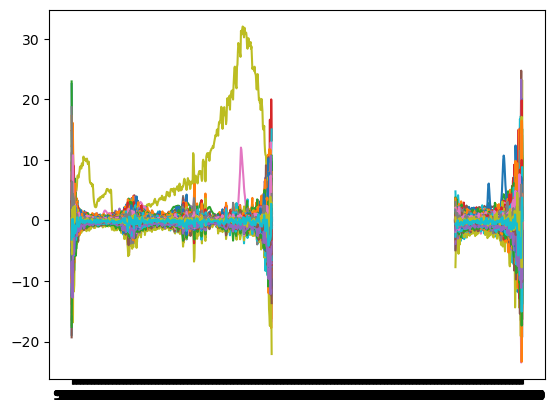

In [4]:
plt.plot(spectra_data.iloc[:,:-4].T)

In [3]:
kmeans_1 = pickle.load(open('bg_classifier_1.sav', 'rb'))
kmeans_2 = pickle.load(open('bg_classifier_2.sav', 'rb'))

In [4]:
spectra_df_bg = spectra_data.iloc[:,:-4].loc[:, ~np.isnan(spectra_data.iloc[:1,:-4]).to_numpy().flatten()]
spectra_df_bg.iloc[np.where(np.isnan(spectra_df_bg.to_numpy()))[0],
np.where(np.isnan(spectra_df_bg.to_numpy()))[1]] = 0
spectra_df_bg

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2986.0,2988.0,2990.0,2992.0,2994.0,2996.0,2998.0,3000.0,3002.0,3004.0
0,-11.567978,-8.489072,-1.152350,0.708794,-3.288227,-1.589775,-3.776421,-2.346167,-0.045465,-0.148116,...,-3.811683,-2.758303,-7.157756,-5.526591,-5.351269,-4.513754,-8.751558,-17.964540,-16.539026,0
1,2.415524,2.161043,3.101432,-0.131648,0.010973,-0.785929,0.264765,-1.982063,-0.789396,-1.298462,...,0.482766,4.133369,4.845397,1.496127,-3.002814,-5.056242,-1.054667,-6.503963,-1.948584,0
2,2.091296,2.576621,0.202698,-0.773197,-0.846646,0.788147,-0.331404,0.048088,-0.027565,0.135584,...,-1.225524,-1.397169,-1.411703,0.552120,0.595618,-0.367995,0.446687,-1.099244,-0.050441,0
3,4.540631,7.128634,4.997062,6.546412,7.430983,5.325127,6.093488,6.774708,7.569579,8.311155,...,3.047582,0.764034,0.428371,1.811893,-0.181741,-0.659091,-1.417886,-0.333559,-0.454761,0
4,-0.151963,-0.556952,1.351564,1.923421,3.067961,3.989200,4.627495,4.603645,5.063306,5.714118,...,-1.293814,-2.675051,-0.867728,-0.828948,-0.590362,-0.614188,-2.350212,-4.838210,-3.433135,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1196,-0.935864,3.880744,2.929635,0.250051,0.826169,1.393210,2.332591,1.525387,2.856019,2.260079,...,4.256210,1.550815,1.461412,3.734034,2.958908,0.946693,2.238408,1.309739,2.320024,0
1197,1.492764,-0.847856,0.093039,-0.122755,0.282954,0.513692,0.286412,0.364859,0.054606,-0.090947,...,0.067454,-0.339594,-0.469184,-0.130478,-1.270416,-0.641360,0.894723,1.498731,1.316655,0
1198,4.142644,3.919585,3.051866,3.130648,2.458905,3.626340,3.658879,5.209679,6.175647,6.763000,...,0.821418,0.866563,-0.172464,0.602042,1.221649,2.707554,0.633610,2.774026,4.715980,0
1199,-2.263271,-2.069079,-1.473391,-1.528627,-0.082605,-0.594047,0.775992,0.682465,0.072067,-0.738273,...,1.193776,0.033319,-2.288374,-1.505990,-2.366880,-3.042248,-2.088140,3.229438,0.285023,0


In [7]:
pred_1 = kmeans_1.predict(spectra_df_bg)

In [102]:
spectra_bg_1 = spectra_data.loc[pred_1 == 0, 'id']
spectra_bg_1

0        Daycroft_Run3_1
1        Daycroft_Run3_2
2        Daycroft_Run3_3
7        Daycroft_Run3_8
10      Daycroft_Run3_11
              ...       
1192         IAO_Run2_97
1193         IAO_Run2_98
1194         IAO_Run2_99
1195        IAO_Run2_100
1199        IAO_Run2_104
Name: id, Length: 760, dtype: object

In [8]:
pred_2 = kmeans_2.predict(spectra_df_bg.loc[(pred_1 == 0),:])

In [103]:
spectra_bg_2 = spectra_bg_1[np.array([x not in [1,2,3,4,5,7,9] for x in pred_2])]
spectra_bg_2

0        Daycroft_Run3_1
12      Daycroft_Run3_13
13      Daycroft_Run3_14
19      Daycroft_Run3_20
22      Daycroft_Run3_23
              ...       
1185         IAO_Run2_90
1189         IAO_Run2_94
1192         IAO_Run2_97
1193         IAO_Run2_98
1195        IAO_Run2_100
Name: id, Length: 509, dtype: object

In [12]:
pred_1_table = pd.DataFrame({'cluster':pred_1, 'count':1}).groupby('cluster').sum().query('count >= 10')
pred_1_table

,count
cluster,
0,760
2,16
3,26
11,45
12,72
18,10
22,14
23,138
27,10


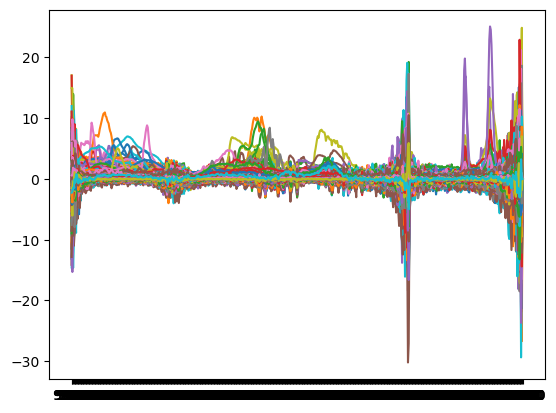

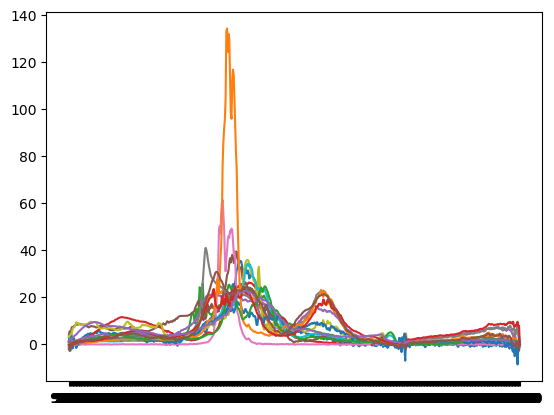

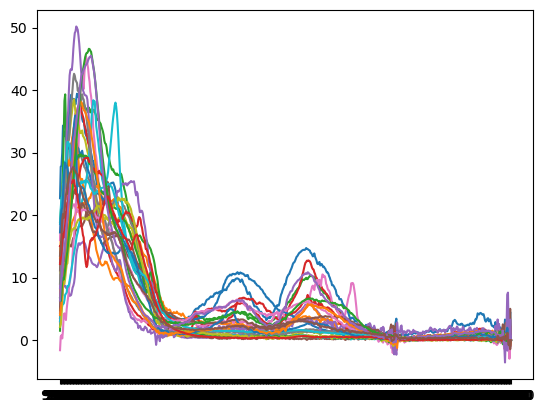

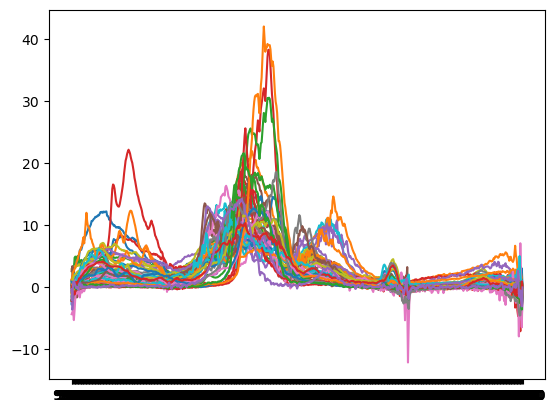

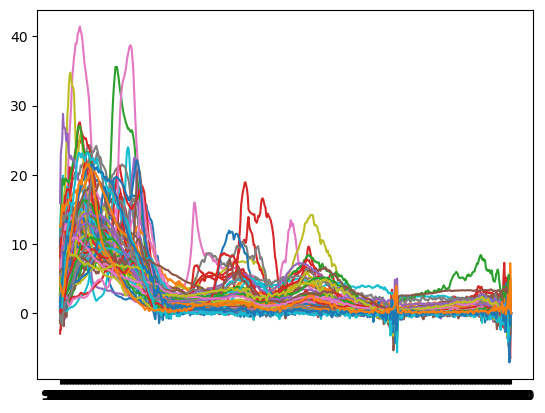

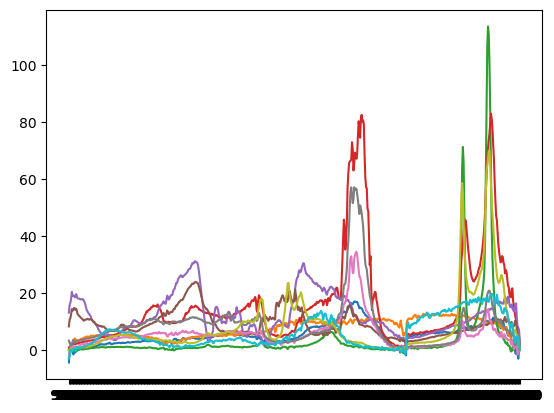

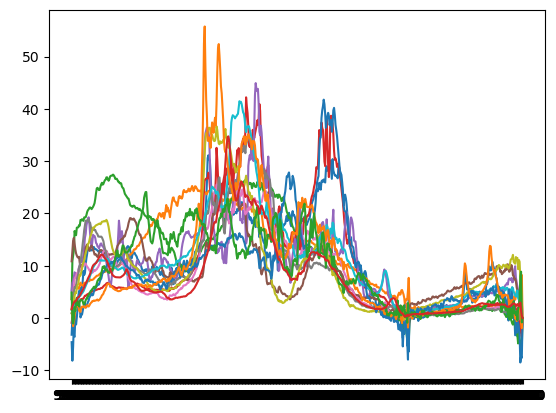

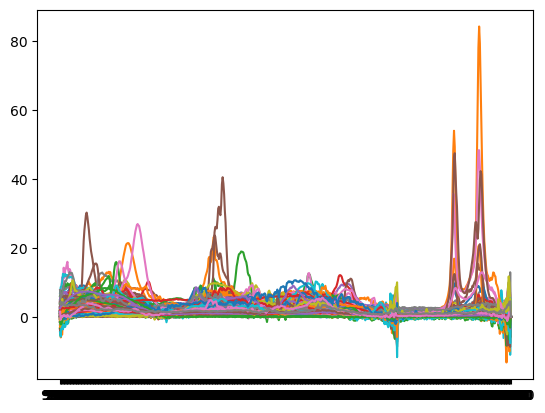

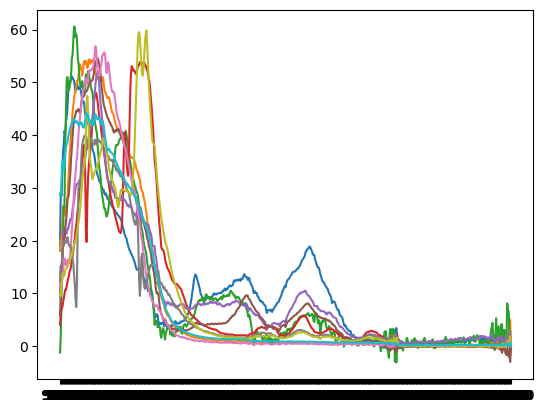

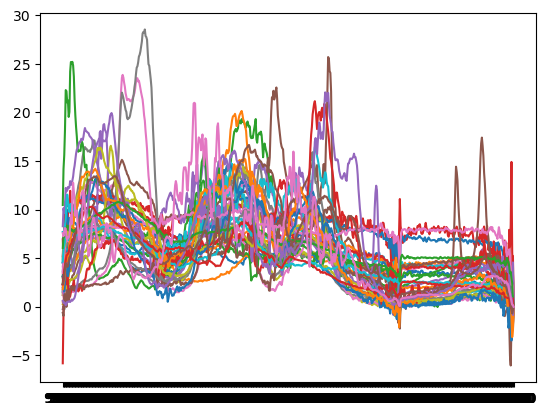

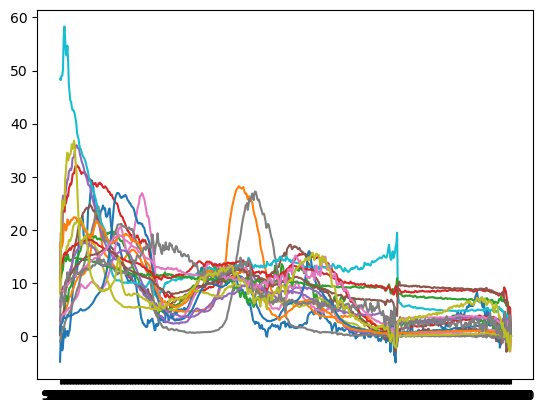

In [14]:
for i in pred_1_table.index:
    _ = plt.plot(spectra_df_bg.loc[(pred_1 == i),:].T)
    plt.show()

In [104]:
pred_2_table = pd.DataFrame({'cluster':pred_2, 'count':1}).groupby('cluster').sum()#.query('count >= 10')
pred_2_table

,count
cluster,
0,217
1,142
2,27
3,18
5,20
6,248
7,39
8,44
9,5


In [ ]:
[1,2,3,4,5,7,9]

0 217


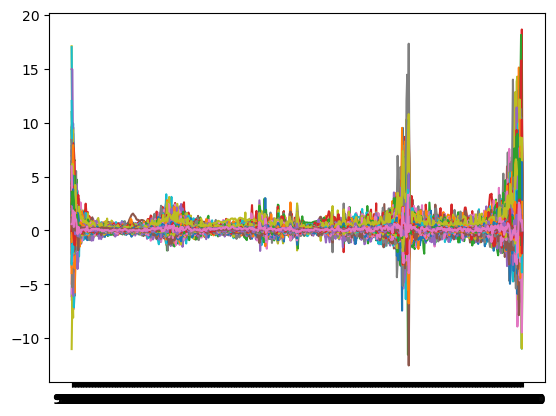

1 142


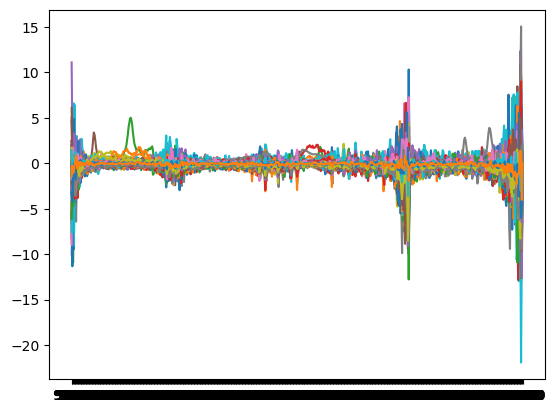

2 27


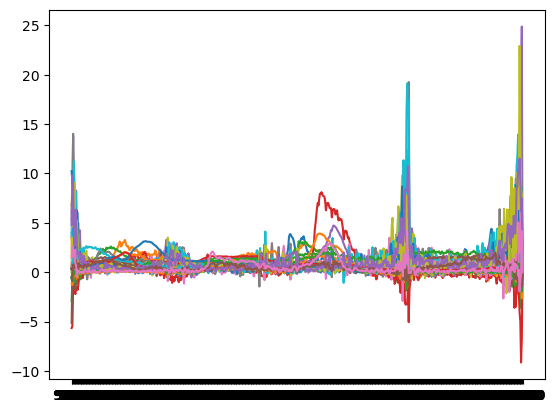

3 18


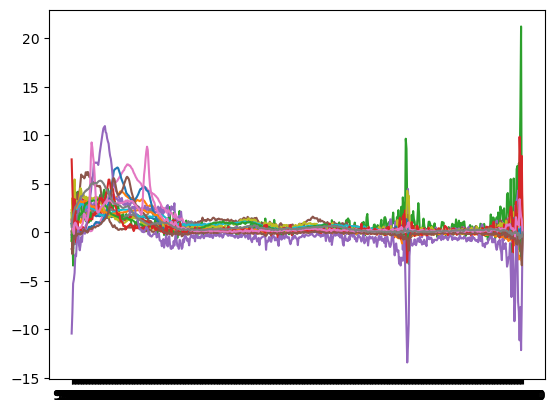

5 20


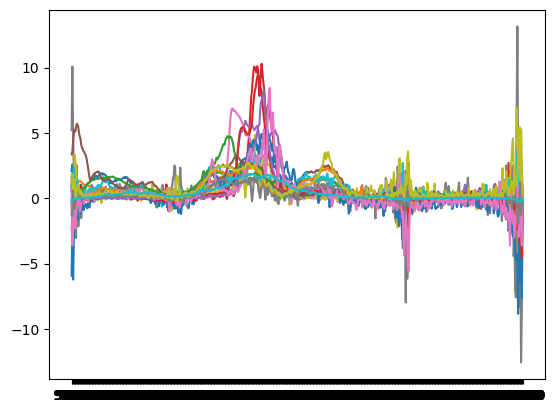

6 248


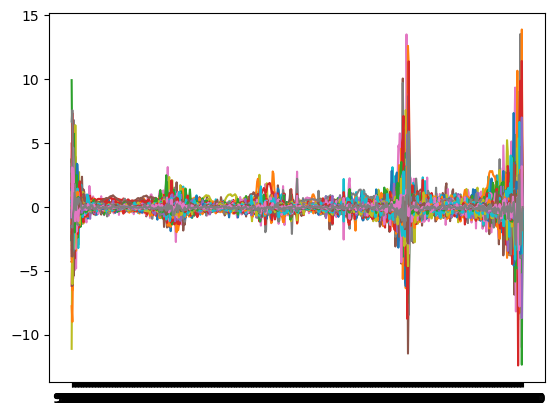

7 39


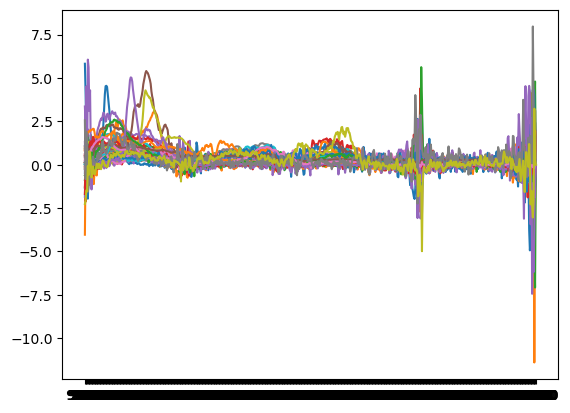

8 44


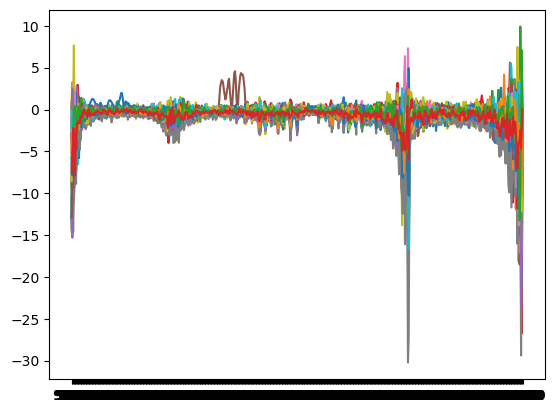

9 5


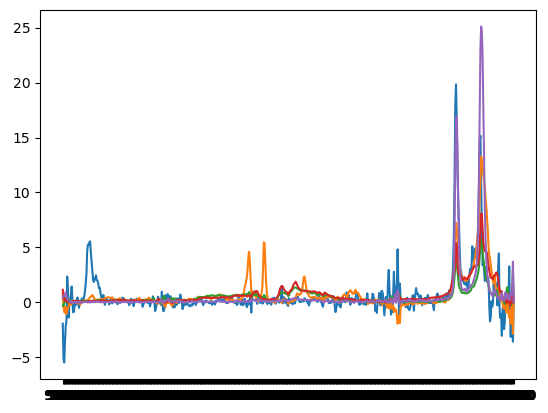

In [105]:
for cluster in pred_2_table.index:
    print(cluster, spectra_df_bg.iloc[(pred_1 == 0),:].iloc[(pred_2 == cluster),:].shape[0])
    _ = plt.plot(spectra_df_bg.loc[(pred_1 == 0),:].loc[(pred_2 == cluster),:].T)
    plt.show()

In [15]:
np.unique(pred_2)

array([0, 1, 2, 6, 8, 9], dtype=int32)

In [ ]:
spectra_bg_2 = spectra_bg_1[np.array([x not in [1,2,3,4,5,7,9] for x in pred_2])]

In [29]:
from sklearn.linear_model import LogisticRegression

In [45]:
x_train_bg = X_train_bg.to_numpy()
y_train_bg = spectra_data_bg_train.iloc[:,-1].to_numpy()

In [69]:
clf = LogisticRegression(random_state=0, C=7, penalty='l1', solver='saga')

In [70]:
clf.fit(x_train_bg, y_train_bg)

LogisticRegression(C=7, penalty='l1', random_state=0, solver='saga')

In [71]:
y_hat_bg_1 = 1*(pred_1 == 0)

In [72]:
y_hat_bg_2 = clf.predict(spectra_df_bg)

In [81]:
pred_1[y_hat_bg_2 == 1]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=int32)

In [73]:
np.mean(y_hat_bg_1 == y_hat_bg_2)

0.6103247293921732

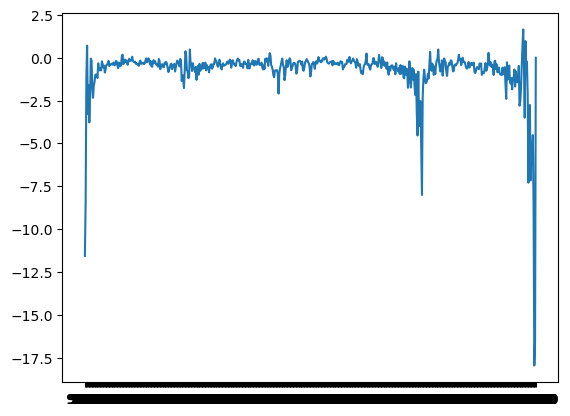

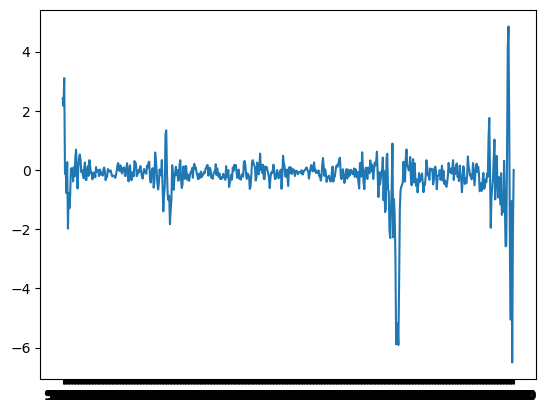

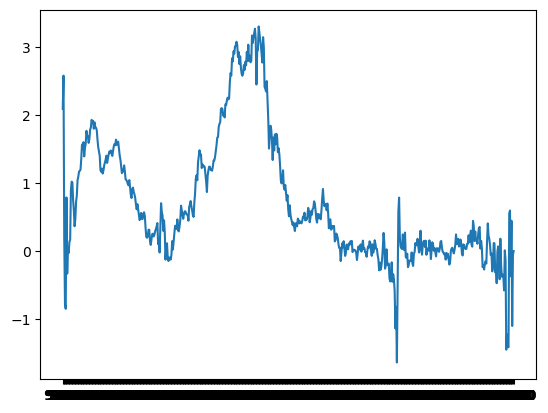

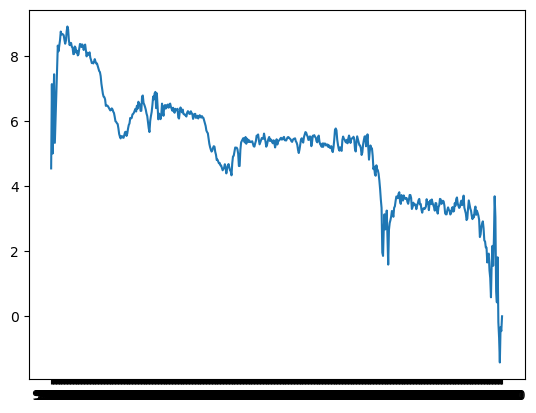

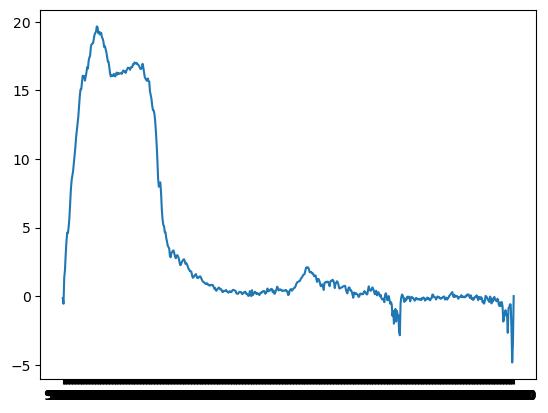

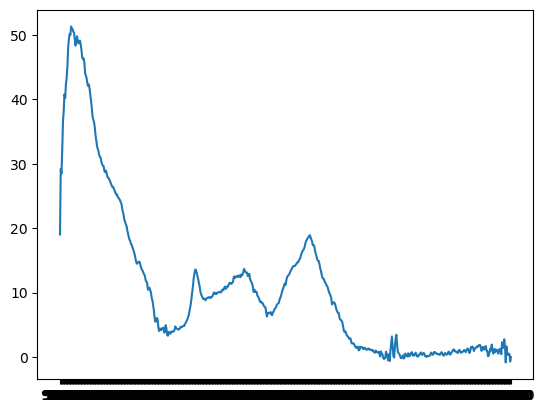

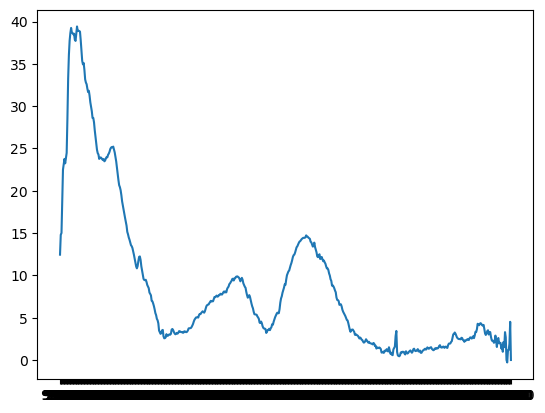

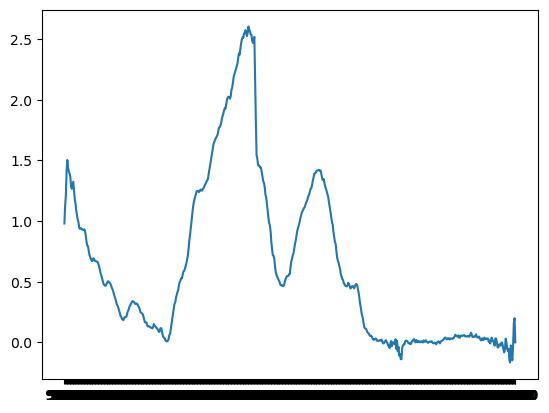

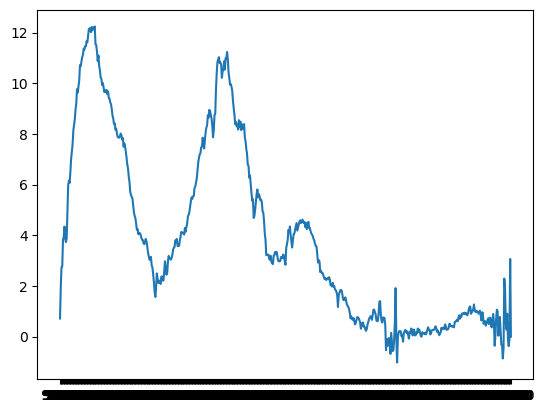

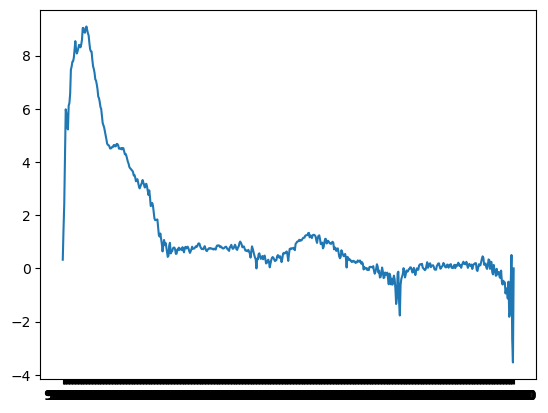

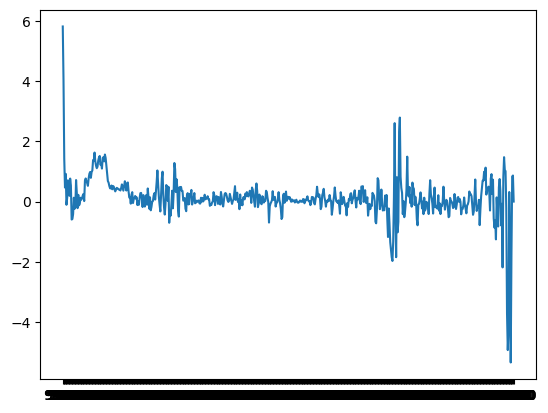

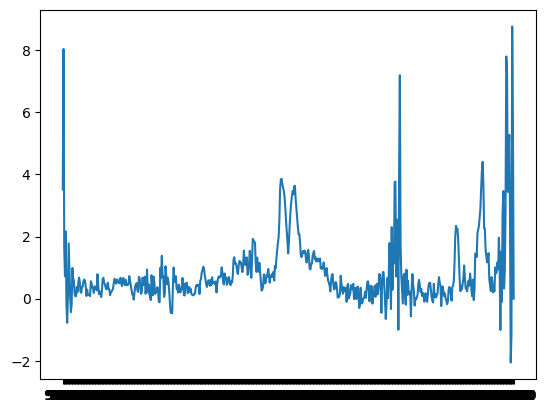

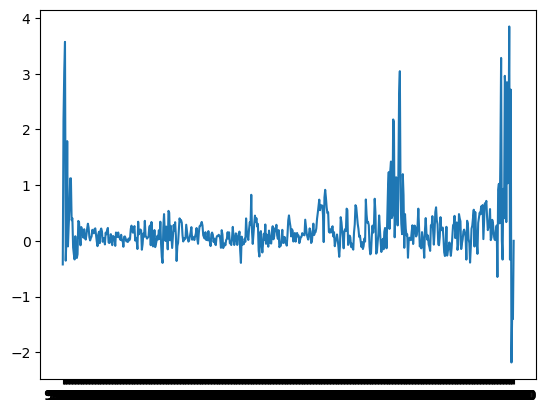

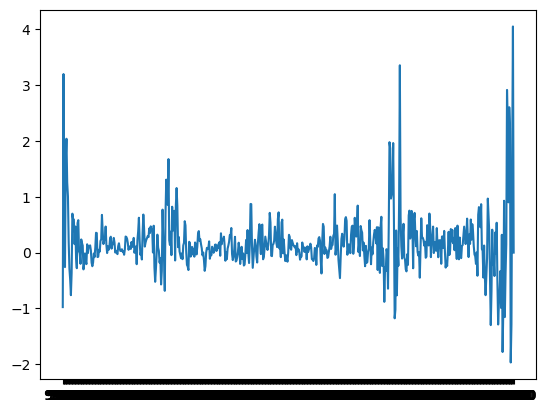

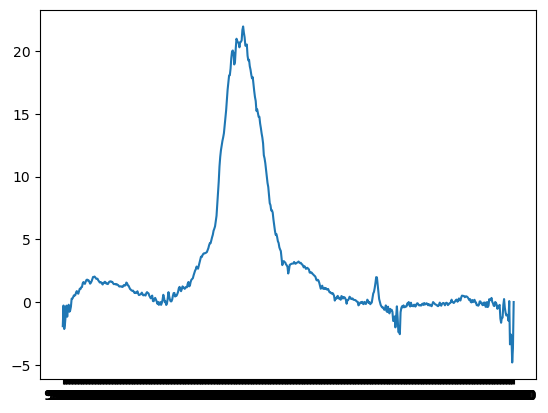

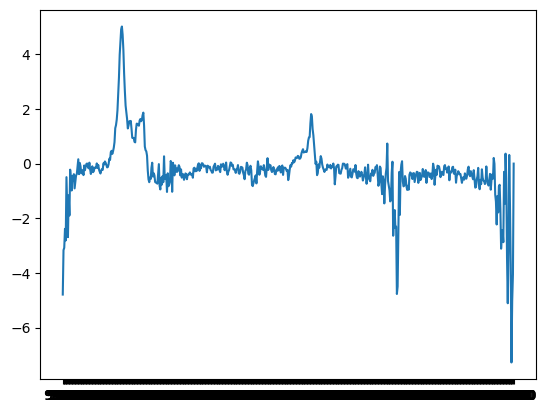

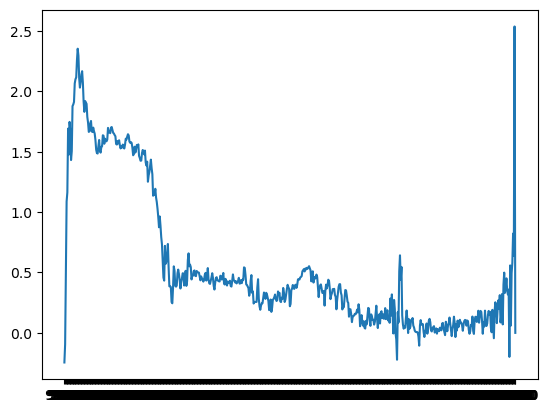

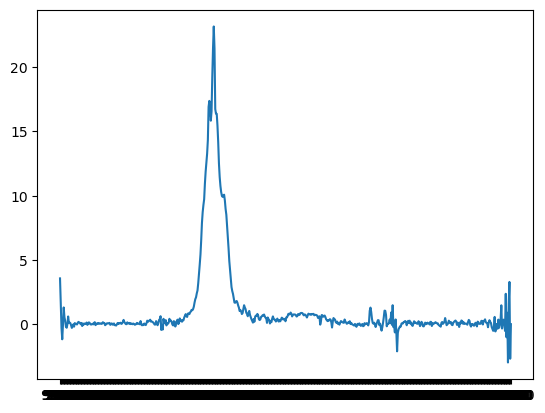

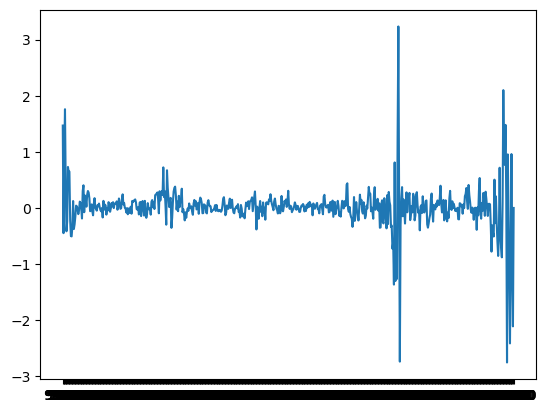

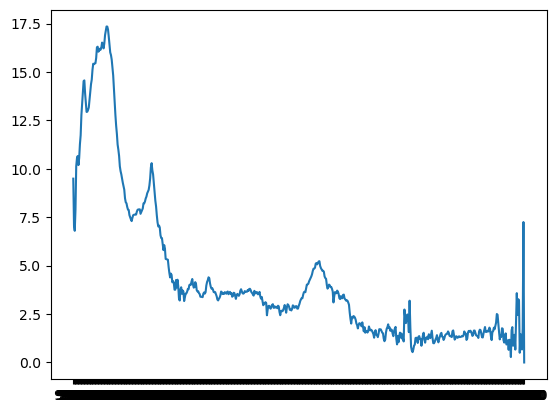

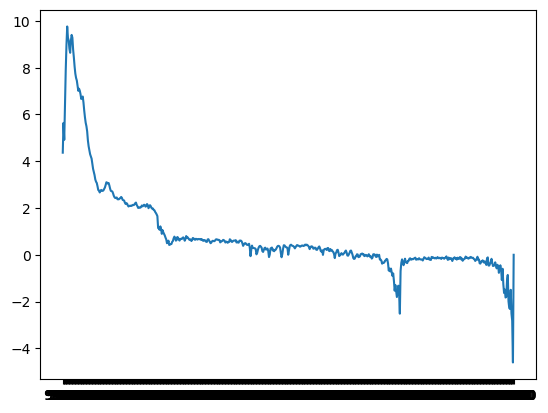

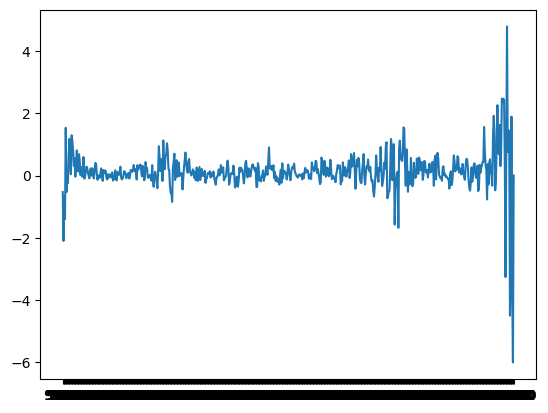

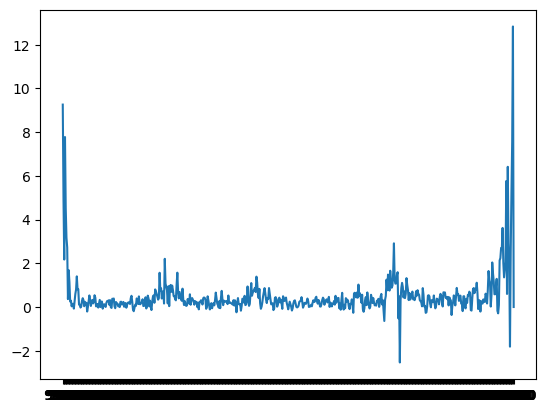

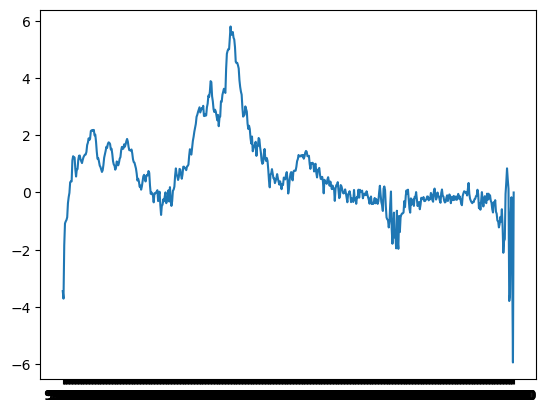

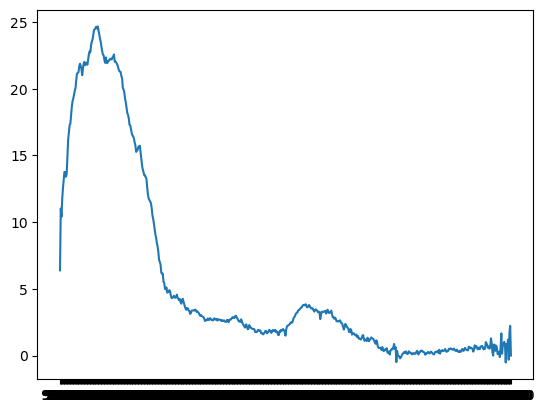

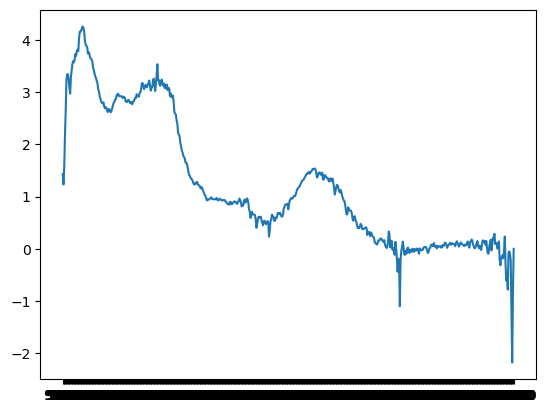

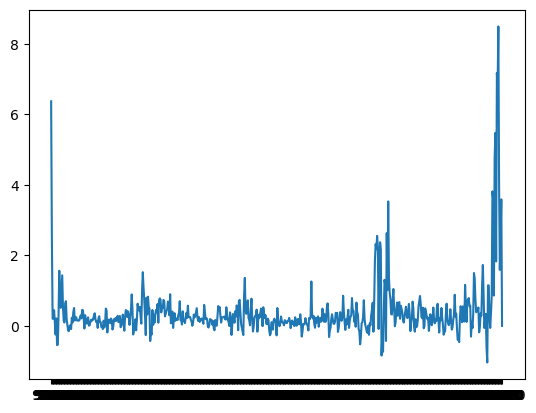

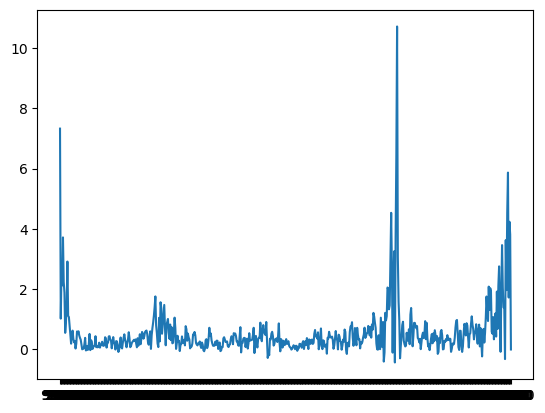

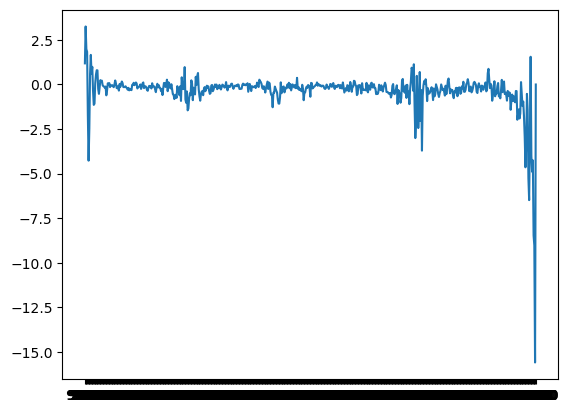

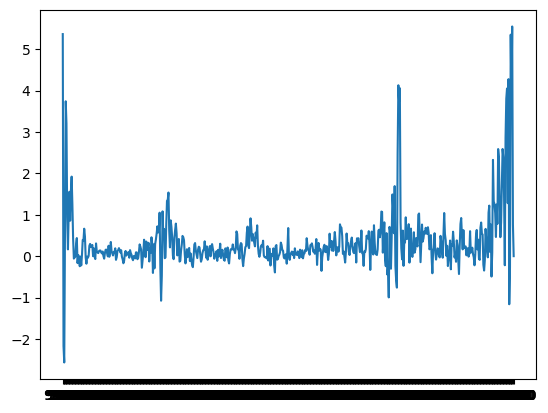

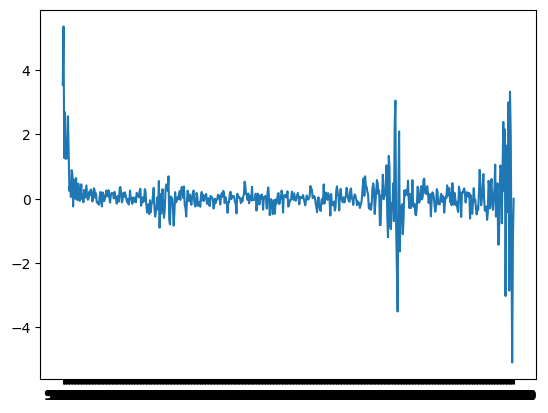

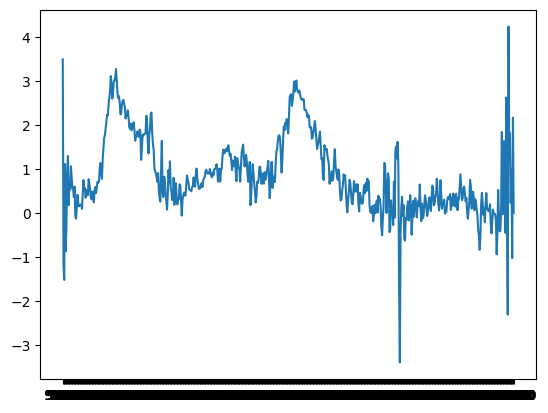

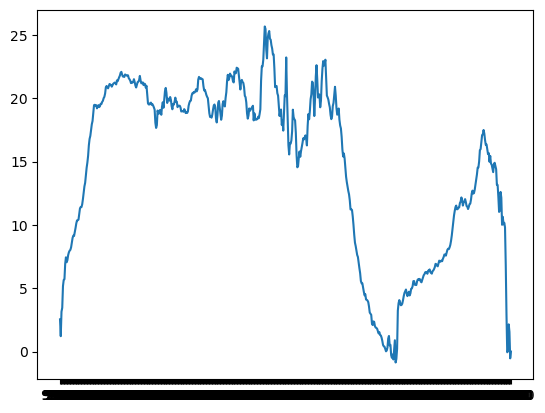

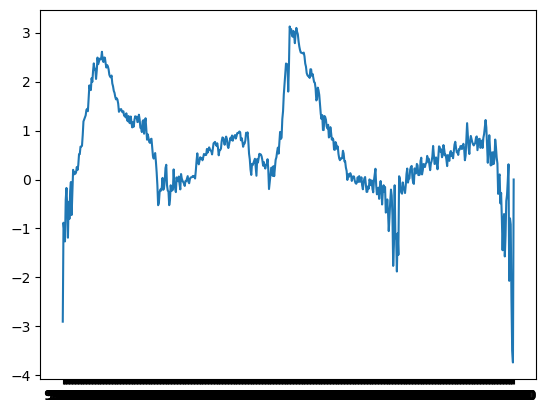

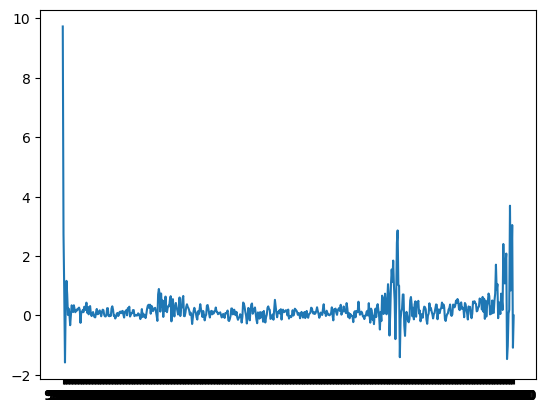

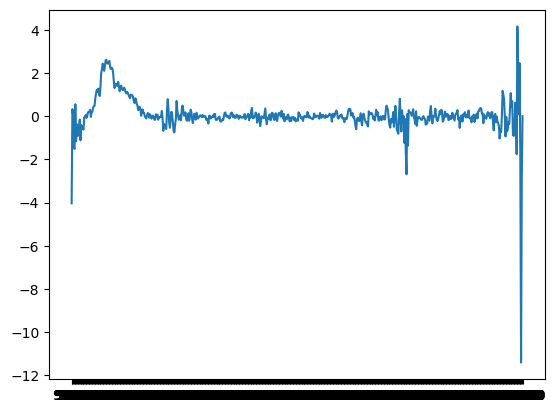

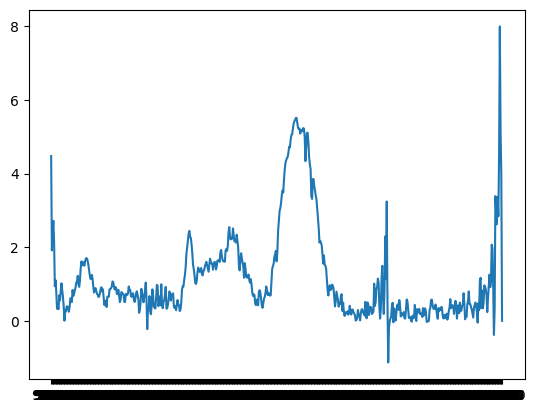

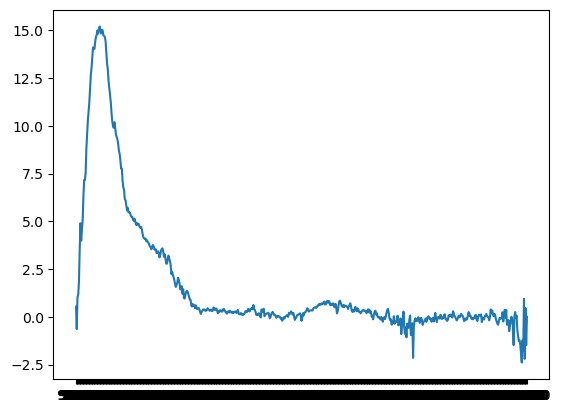

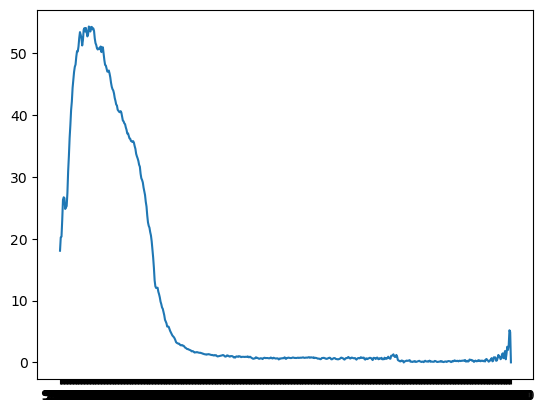

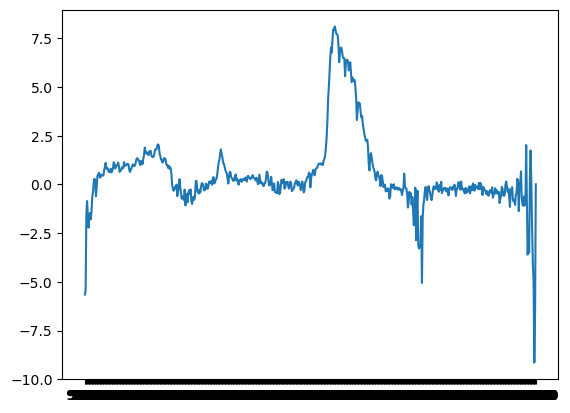

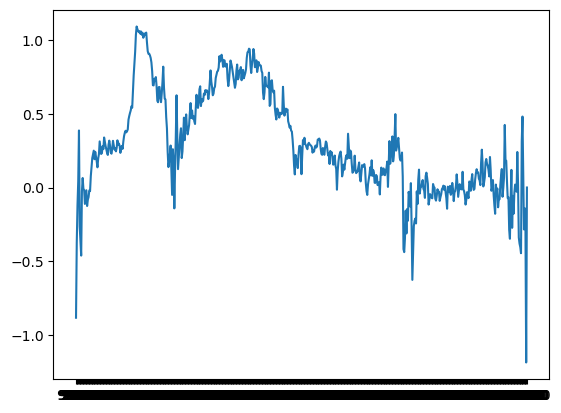

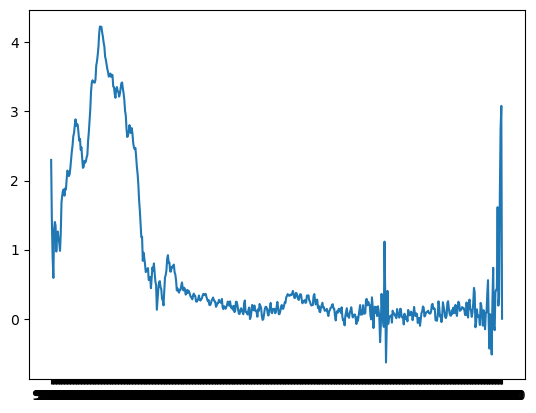

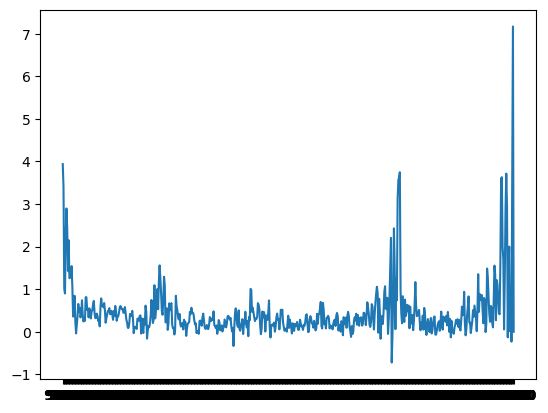

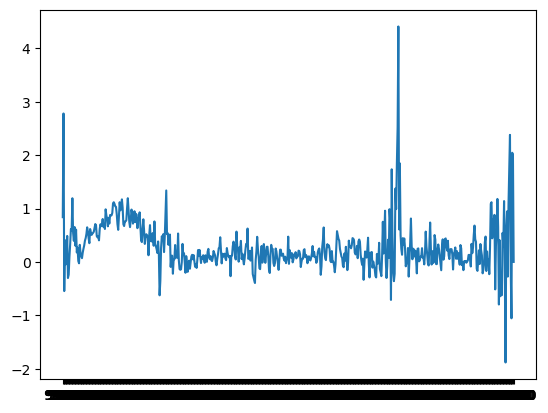

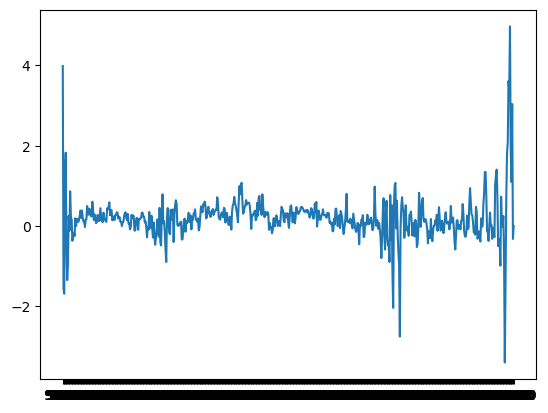

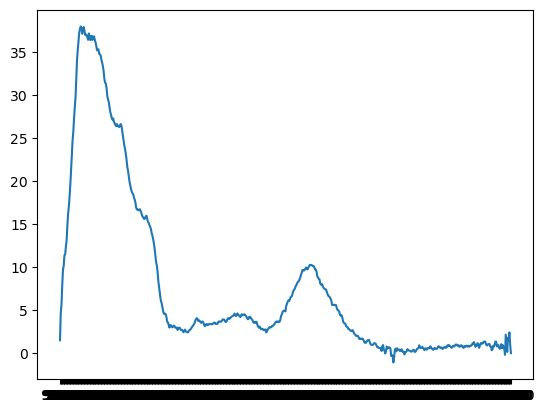

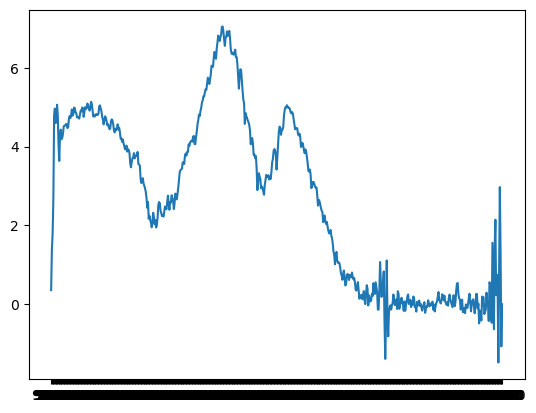

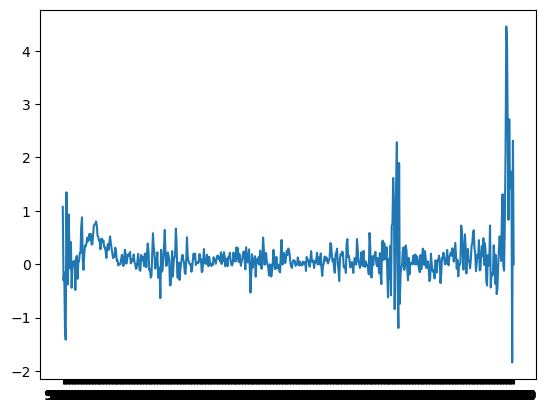

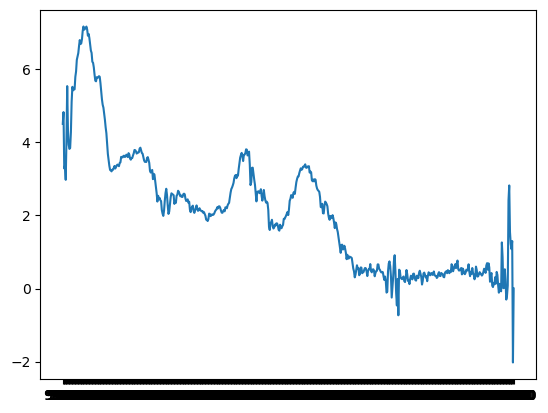

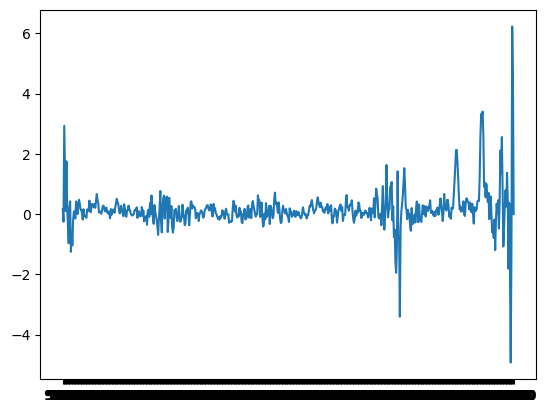

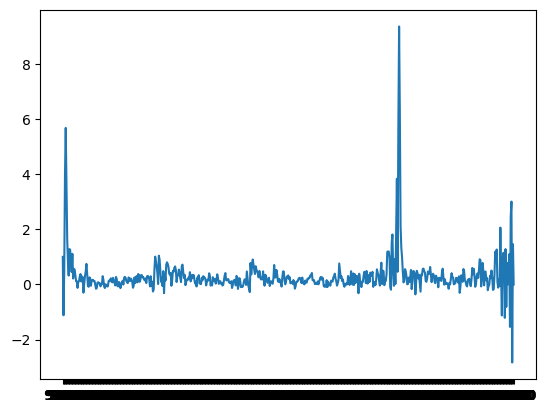

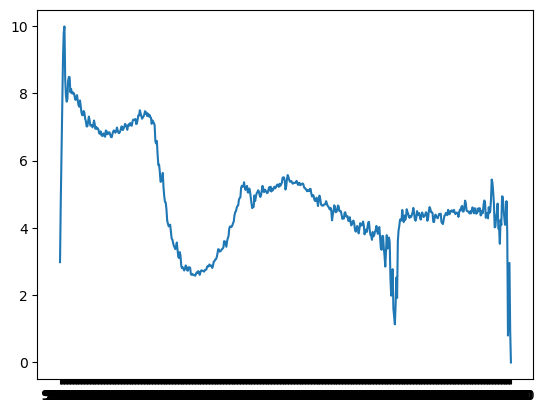

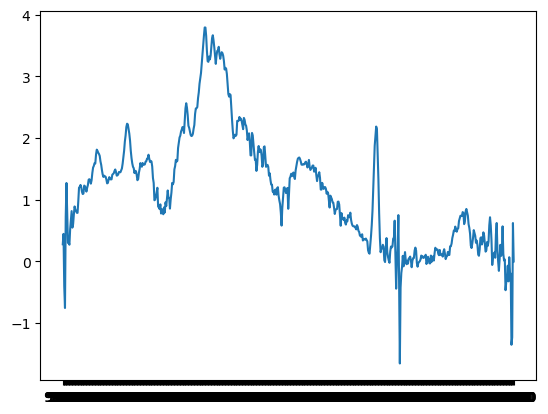

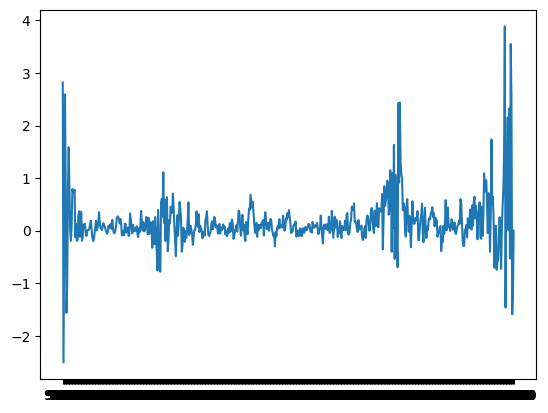

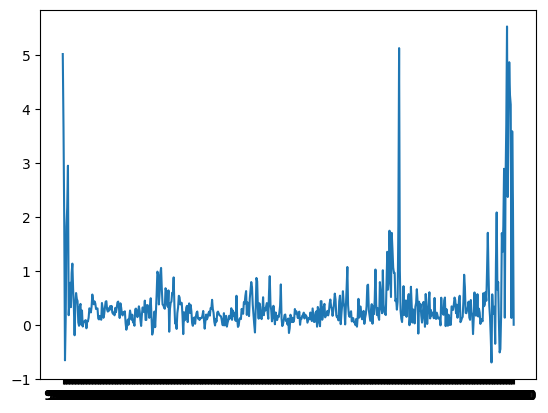

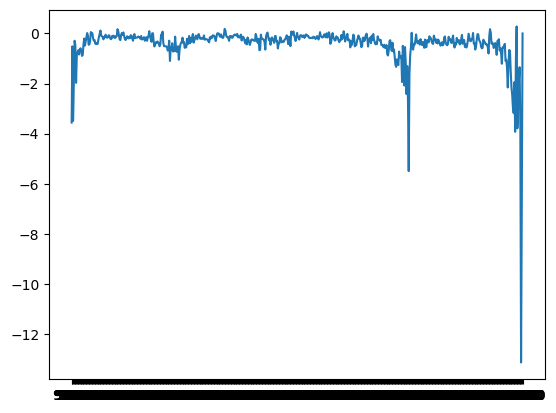

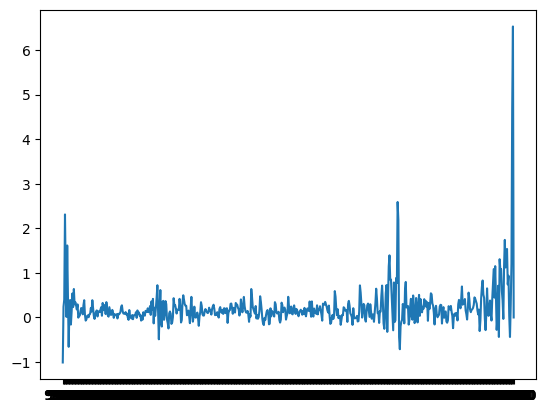

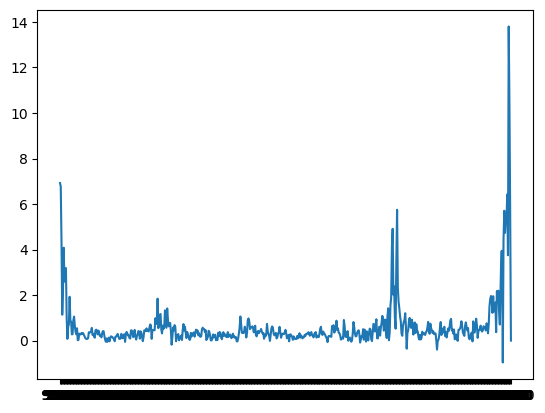

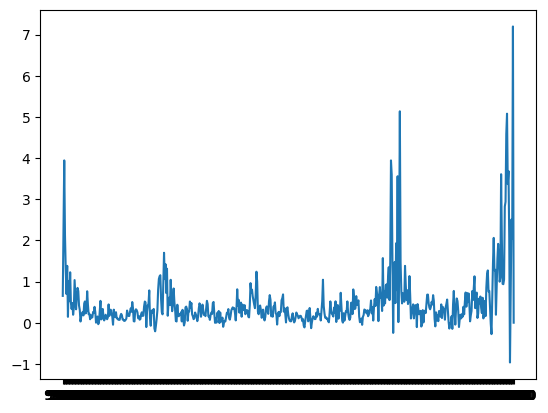

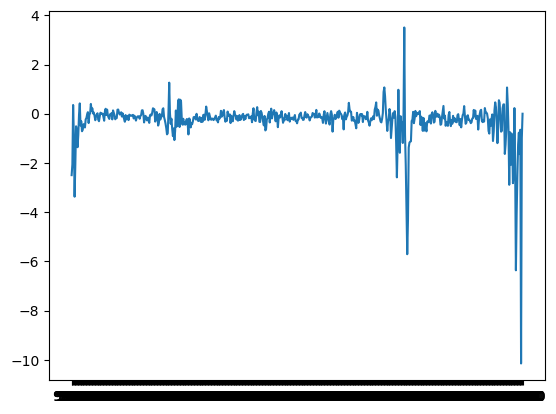

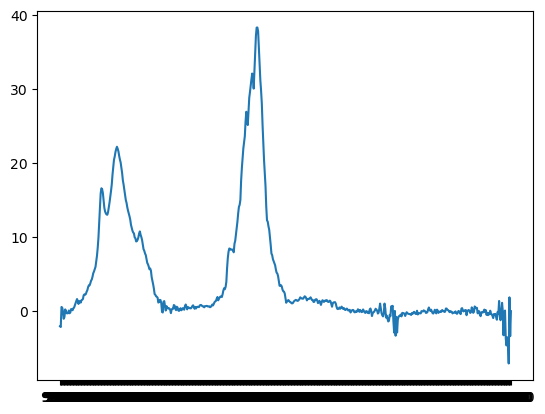

KeyboardInterrupt: 

In [91]:
for i in np.where(y_hat_bg_2==0)[0]:
    _ = plt.plot(spectra_df_bg.iloc[i,:].T)
    _ = plt.show()

In [87]:
np.where(y_hat_bg_2==0)[0].shape

(909,)

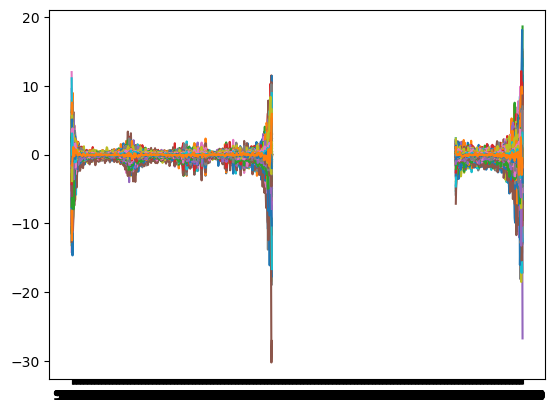

In [99]:
_ = plt.plot(spectra_data.iloc[np.where(y_hat_bg_2==1)[0],:-5].T)

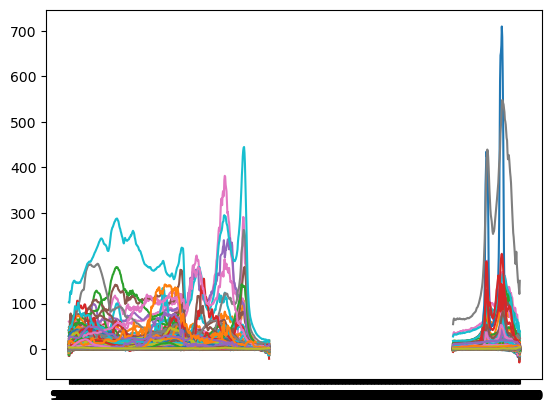

In [98]:
_ = plt.plot(spectra_data.iloc[np.where(y_hat_bg_2==0)[0],:-5].T)

In [100]:
spectra_data.iloc[np.where(y_hat_bg_2==0)[0],:]

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2994.0,2996.0,2998.0,3000.0,3002.0,3004.0,id,school,run,sample_id
0,-11.567978,-8.489072,-1.152350,0.708794,-3.288227,-1.589775,-3.776421,-2.346167,-0.045465,-0.148116,...,-5.351269,-4.513754,-8.751558,-17.964540,-16.539026,0,Daycroft_Run3_1,Daycroft,Run3,1
1,2.415524,2.161043,3.101432,-0.131648,0.010973,-0.785929,0.264765,-1.982063,-0.789396,-1.298462,...,-3.002814,-5.056242,-1.054667,-6.503963,-1.948584,0,Daycroft_Run3_2,Daycroft,Run3,2
2,2.091296,2.576621,0.202698,-0.773197,-0.846646,0.788147,-0.331404,0.048088,-0.027565,0.135584,...,0.595618,-0.367995,0.446687,-1.099244,-0.050441,0,Daycroft_Run3_3,Daycroft,Run3,3
3,4.540631,7.128634,4.997062,6.546412,7.430983,5.325127,6.093488,6.774708,7.569579,8.311155,...,-0.181741,-0.659091,-1.417886,-0.333559,-0.454761,0,Daycroft_Run3_4,Daycroft,Run3,4
4,-0.151963,-0.556952,1.351564,1.923421,3.067961,3.989200,4.627495,4.603645,5.063306,5.714118,...,-0.590362,-0.614188,-2.350212,-4.838210,-3.433135,0,Daycroft_Run3_5,Daycroft,Run3,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1196,-0.935864,3.880744,2.929635,0.250051,0.826169,1.393210,2.332591,1.525387,2.856019,2.260079,...,2.958908,0.946693,2.238408,1.309739,2.320024,0,IAO_Run2_101,IAO,Run2,101
1197,1.492764,-0.847856,0.093039,-0.122755,0.282954,0.513692,0.286412,0.364859,0.054606,-0.090947,...,-1.270416,-0.641360,0.894723,1.498731,1.316655,0,IAO_Run2_102,IAO,Run2,102
1198,4.142644,3.919585,3.051866,3.130648,2.458905,3.626340,3.658879,5.209679,6.175647,6.763000,...,1.221649,2.707554,0.633610,2.774026,4.715980,0,IAO_Run2_103,IAO,Run2,103
1199,-2.263271,-2.069079,-1.473391,-1.528627,-0.082605,-0.594047,0.775992,0.682465,0.072067,-0.738273,...,-2.366880,-3.042248,-2.088140,3.229438,0.285023,0,IAO_Run2_104,IAO,Run2,104


In [106]:
path = 'OPTIR/Pilot_Phase_Field_Samples_subs2/'
spectra_data.query('id not in @spectra_bg_2').reset_index(drop=True).to_csv(path + 'data_non_background.csv')
spectra_data.query('id in @spectra_bg_2').reset_index(drop=True).to_csv(path + '/data_background.csv')

In [101]:
path = 'OPTIR/Pilot_Phase_Field_Samples_subs2/'
spectra_data.iloc[np.where(y_hat_bg_2==0)[0],:].reset_index(drop=True).to_csv(path + 'data_non_background.csv')
spectra_data.iloc[np.where(y_hat_bg_2==1)[0],:].reset_index(drop=True).to_csv(path + '/data_background.csv')